Name: Moksh Barapatre

Section: B3

Batch: B3

Roll no.:49

In [1]:
import sys
import pandas as pd
import numpy as np
import requests
import bs4
import matplotlib
import scipy
import sklearn
import gradio

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Requests:", requests.__version__)
print("BeautifulSoup:", bs4.__version__)
print("Matplotlib:", matplotlib.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Gradio:", gradio.__version__)

Python: 3.13.15
Pandas: 2.2.3
NumPy: 2.1.3
Requests: 2.32.4
BeautifulSoup: 4.13.5
Matplotlib: 3.10.0
SciPy: 1.16.3
Scikit-learn: 1.6.1
Gradio: 6.30.0


In [2]:
import os
import re
from io import StringIO
import warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Reproducibility and optional demo configuration
SEED = 42
RUN_GRADIO_DEMO = False  # Set to True to launch the Gradio interface


In [3]:
salary_raw = pd.read_csv("india_salary_benchmarks_2026_sample.csv")
layoffs_raw = pd.read_csv("layoffs-2026.csv", comment="#")

print("Salary dataset:", salary_raw.shape)
print("Layoffs dataset:", layoffs_raw.shape)

print("Salary columns:", salary_raw.columns.tolist())
print("Layoffs columns:", layoffs_raw.columns.tolist())

display(layoffs_raw.head(5))

Salary dataset: (12958, 14)
Layoffs dataset: (557, 8)
Salary columns: ['posting_id', 'posted_month', 'company', 'company_domain', 'job_title', 'role_family', 'seniority', 'experience_band', 'city', 'industry_category', 'salary_min_inr', 'salary_max_inr', 'salary_mid_inr', 'fliar_profile_url']
Layoffs columns: ['Company', 'Industry', 'People Cut', 'Workforce %', 'Total Workforce', 'Date', 'Category', 'Source URL']


,Company,Industry,People Cut,Workforce %,Total Workforce,Date,Category,Source URL
0,HMSHost,Retail,135,0.7%,20745,Oct 23,RESTRUCTURE,https://mynorthwest.com/money/starbucks-sea-la...
1,PandaDoc,Tech,103,14.7%,700,Oct 20,RESTRUCTURE,https://dev.ua/en/news/zvilnennia-v-pandadoc-1...
2,The Blade (Toledo),Media & Entertainment,116,97.5%,119,Oct 23,RESTRUCTURE,https://www.13abc.com/2026/10/23/toledo-blade-...
3,The Andersons,Manufacturing,64,3.2%,2028,Oct 20,RESTRUCTURE,https://workforce.alabama.gov/warn-list/
4,EyePoint,Healthcare & Pharma,113,52.8%,214,Oct 19,RESTRUCTURE,https://www.biospace.com/job-trends/eyepoint-w...


In [4]:
SALARY_PAGE_URL = "https://fliarbi.com/datasets/india-salary-benchmarks-2026/"
LAYOFFS_CSV_URL = "https://layoffhedge.com/data/layoffs-2026.csv"

def inspect_webpage(url, timeout=8):
    response = requests.get(url, timeout=timeout)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    result = {
        "url": url,
        "status": response.status_code,
        "title": soup.title.get_text(strip=True) if soup.title else "No title",
        "text_preview": soup.get_text(" ", strip=True)[:350],
        "table_count": len(pd.read_html(StringIO(response.text))),
        "error": None
    }

    return result, response.text


salary_page_check, salary_html = inspect_webpage(SALARY_PAGE_URL)

print("Salary webpage check:")
display(pd.DataFrame([salary_page_check]).drop(columns=["text_preview"]))

print("Page text preview:", salary_page_check["text_preview"])

soup = BeautifulSoup(salary_html, "html.parser")

print("Extracted heading tags:")
print([h.get_text(strip=True) for h in soup.find_all(["h1", "h2", "h3"])[:8]])

tables = pd.read_html(StringIO(salary_html))

if tables:
    print("First HTML table preview:")
    display(tables[0].head())
else:
    print("No HTML tables were found.")

Salary webpage check:


,url,status,title,table_count,error
0,https://fliarbi.com/datasets/india-salary-benc...,200,India Salary Data 2026: 49k Job Postings — dat...,9,None


Page text preview: India Salary Data 2026: 49k Job Postings — dataset, sample CSV and API | Fliar BI Companies RADAR Home Directory Explore Datasets Dashboard Sign In Get Pro dashboard Dashboard Fliar BI / Datasets / India Salary Data 2026: 49k Job Postings Jobs & Salaries · India Open dataset · updated 2026-10-17 India Salary Data 2026: 49k Job Postings India salary
Extracted heading tags:
['India Salary Data 2026: 49k Job Postings', 'Key findings', 'Salary percentiles by role family and seniority (INR per year)', 'Top 50 Indian cities by salaried postings', 'Top 50 highest-paying job titles in India', 'Salary by industry / functional category', 'Salary by years of experience asked', 'Salary by role family']
First HTML table preview:


,Role family,Seniority,Postings,Employers,10th pct,25th pct,Median,75th pct,90th pct
0,Administration,entry,258,191,₹1.8L,₹2.2L,₹3.0L,₹4.0L,₹5.8L
1,Administration,mid,393,263,₹3.0L,₹4.2L,₹6.0L,₹8.0L,₹14.0L
2,Administration,senior,173,109,₹4.5L,₹6.8L,₹10.0L,₹17.0L,₹26.2L
3,Administration,lead,30,26,₹5.8L,₹7.9L,₹14.1L,₹22.2L,₹25.2L
4,Administration,manager,32,31,₹2.8L,₹4.9L,₹5.8L,₹12.8L,₹21.8L


In [5]:
layoffs_url_check = {
    "url": LAYOFFS_CSV_URL,
    "status": None,
    "downloaded_bytes": None,
    "parsed_rows": None,
    "error": None
}

response = requests.get(LAYOFFS_CSV_URL, timeout=8)
layoffs_url_check["status"] = response.status_code
response.raise_for_status()


downloaded_layoffs = pd.read_csv(StringIO(response.text), comment="#")

layoffs_url_check["downloaded_bytes"] = len(response.content)
layoffs_url_check["parsed_rows"] = len(downloaded_layoffs)

print("Downloaded CSV preview:")
display(downloaded_layoffs.head())

print("Live CSV URL validation:")
display(pd.DataFrame([layoffs_url_check]))


Downloaded CSV preview:


,Company,Industry,People Cut,Workforce %,Total Workforce,Date,Category,Source URL
0,Foster USA,Consumer Goods,181,100.0%,181,Oct 21,WEAK DEMAND,https://wcti12.com/news/local/warn-filing-list...
1,S&S Worldwide,Retail,70,25.5%,275,Oct 20,RESTRUCTURE,https://patch.com/connecticut/across-ct/mass-l...
2,From the Ground Up (Our Home),Consumer Goods,93,7.8%,1200,Oct 19,RESTRUCTURE,https://www.wbtv.com/2026/10/26/nearly-100-wor...
3,HMSHost,Retail,135,0.7%,20745,Oct 23,RESTRUCTURE,https://mynorthwest.com/money/starbucks-sea-la...
4,PandaDoc,Tech,103,14.7%,700,Oct 20,RESTRUCTURE,https://dev.ua/en/news/zvilnennia-v-pandadoc-1...


Live CSV URL validation:


,url,status,downloaded_bytes,parsed_rows,error
0,https://layoffhedge.com/data/layoffs-2026.csv,200,92745,560,None


# EDA

In [6]:
print("SALARY RAW SHAPE:", salary_raw.shape)
print("SALARY DTYPES:")
display(salary_raw.dtypes.rename("dtype").to_frame())
print("Salary missing values:")
display(salary_raw.isna().sum().rename("missing_count").to_frame())
print("Salary duplicate rows:", int(salary_raw.duplicated().sum()))

salary_clean = salary_raw.copy()
for col in ["salary_min_inr", "salary_max_inr", "salary_mid_inr"]:
    if col in salary_clean:
        salary_clean[col] = pd.to_numeric(salary_clean[col], errors="coerce")
salary_clean = salary_clean.drop_duplicates().copy()
salary_clean = salary_clean[salary_clean["salary_mid_inr"].notna() & (salary_clean["salary_mid_inr"] > 0)].copy()
salary_clean["posted_month_dt"] = pd.to_datetime(salary_clean["posted_month"], errors="coerce")
salary_clean["month_index"] = (salary_clean["posted_month_dt"].dt.year * 12 + salary_clean["posted_month_dt"].dt.month)
print("Salary analysis shape after duplicate removal and valid positive midpoint filter:", salary_clean.shape)
display(salary_clean[["job_title","role_family","seniority","experience_band","city","salary_mid_inr"]].head())
display(salary_clean["salary_mid_inr"].describe().to_frame().round(2))

SALARY RAW SHAPE: (12958, 14)
SALARY DTYPES:


,dtype
posting_id,object
posted_month,object
company,object
company_domain,object
job_title,object
role_family,object
seniority,object
experience_band,object
city,object
industry_category,object


Salary missing values:


,missing_count
posting_id,0
posted_month,0
company,0
company_domain,11519
job_title,0
role_family,0
seniority,955
experience_band,1093
city,341
industry_category,6380


Salary duplicate rows: 0
Salary analysis shape after duplicate removal and valid positive midpoint filter: (12958, 16)


,job_title,role_family,seniority,experience_band,city,salary_mid_inr
0,iOS Developer,software-eng,entry,0-1 yrs,Madurai,450000
1,Sr. Dotnet Developer,software-eng,senior,2-3 yrs,Ahmedabad,650000
2,SEO Executive,marketing,mid,2-3 yrs,Kolkata,1050000
3,Quality Assurance Intern,other,intern,0-1 yrs,Gurugram,90000
4,Senior E-commerce manager,other,manager,2-3 yrs,Faridabad,250000


,salary_mid_inr
count,12958.00
mean,1016846.91
std,1349484.98
min,30000.00
25%,350000.00
50%,600000.00
75%,1150000.00
max,24600000.00


In [7]:
print("LAYOFFS RAW SHAPE:", layoffs_raw.shape)
print("Layoffs dtypes:")
display(layoffs_raw.dtypes.rename("dtype").to_frame())
print("Layoffs missing values:")
display(layoffs_raw.isna().sum().rename("missing_count").to_frame())
print("Layoffs duplicate rows:", int(layoffs_raw.duplicated().sum()))

layoffs_clean = layoffs_raw.drop_duplicates().copy()
for col in ["People Cut", "Total Workforce"]:
    if col in layoffs_clean:
        layoffs_clean[col] = pd.to_numeric(layoffs_clean[col].astype(str).str.replace(",", "", regex=False), errors="coerce")
if "Workforce %" in layoffs_clean:
    layoffs_clean["Workforce_pct"] = pd.to_numeric(layoffs_clean["Workforce %"].astype(str).str.replace("%", "", regex=False), errors="coerce")
if "Date" in layoffs_clean:
    layoffs_clean["date_parsed"] = pd.to_datetime(layoffs_clean["Date"].astype(str) + " 2026", format="%b %d %Y", errors="coerce")
print("Layoffs analysis shape:", layoffs_clean.shape)
display(layoffs_clean.head())
if "People Cut" in layoffs_clean:
    display(layoffs_clean[["People Cut","Total Workforce","Workforce_pct"]].describe().round(2))

LAYOFFS RAW SHAPE: (557, 8)
Layoffs dtypes:


,dtype
Company,object
Industry,object
People Cut,int64
Workforce %,object
Total Workforce,int64
Date,object
Category,object
Source URL,object


Layoffs missing values:


,missing_count
Company,0
Industry,0
People Cut,0
Workforce %,0
Total Workforce,0
Date,0
Category,0
Source URL,0


Layoffs duplicate rows: 0
Layoffs analysis shape: (557, 10)


,Company,Industry,People Cut,Workforce %,Total Workforce,Date,Category,Source URL,Workforce_pct,date_parsed
0,HMSHost,Retail,135,0.7%,20745,Oct 23,RESTRUCTURE,https://mynorthwest.com/money/starbucks-sea-la...,0.7,2026-10-23
1,PandaDoc,Tech,103,14.7%,700,Oct 20,RESTRUCTURE,https://dev.ua/en/news/zvilnennia-v-pandadoc-1...,14.7,2026-10-20
2,The Blade (Toledo),Media & Entertainment,116,97.5%,119,Oct 23,RESTRUCTURE,https://www.13abc.com/2026/10/23/toledo-blade-...,97.5,2026-10-23
3,The Andersons,Manufacturing,64,3.2%,2028,Oct 20,RESTRUCTURE,https://workforce.alabama.gov/warn-list/,3.2,2026-10-20
4,EyePoint,Healthcare & Pharma,113,52.8%,214,Oct 19,RESTRUCTURE,https://www.biospace.com/job-trends/eyepoint-w...,52.8,2026-10-19


,People Cut,Total Workforce,Workforce_pct
count,557.00,557.00,557.00
mean,1275.62,64030.75,12.16
std,4001.86,184510.66,19.36
min,19.00,25.00,0.00
25%,100.00,1700.00,0.80
50%,206.00,10000.00,5.00
75%,660.00,42600.00,14.70
max,50000.00,2100000.00,100.00


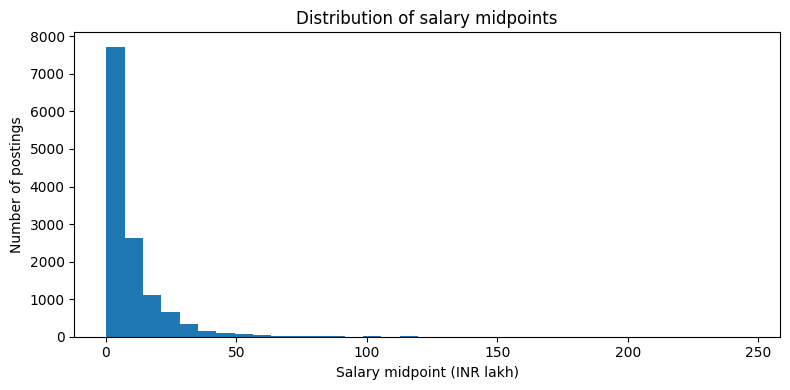

IQR outlier rule: Q1=350,000 INR, Q3=1,150,000 INR, IQR=800,000 INR.
Potential outliers: 1226 of 12958 records. These are flagged for inspection, not automatically removed.


In [8]:
plt.figure(figsize=(8, 4))
plt.hist(salary_clean["salary_mid_inr"] / 100000, bins=35)
plt.xlabel("Salary midpoint (INR lakh)")
plt.ylabel("Number of postings")
plt.title("Distribution of salary midpoints")
plt.tight_layout()
plt.show()

q1, q3 = salary_clean["salary_mid_inr"].quantile([0.25, 0.75])
iqr = q3 - q1
outlier_count = int(((salary_clean["salary_mid_inr"] < q1 - 1.5*iqr) | (salary_clean["salary_mid_inr"] > q3 + 1.5*iqr)).sum())
print(f"IQR outlier rule: Q1={q1:,.0f} INR, Q3={q3:,.0f} INR, IQR={iqr:,.0f} INR.")
print(f"Potential outliers: {outlier_count} of {len(salary_clean)} records. These are flagged for inspection, not automatically removed.")

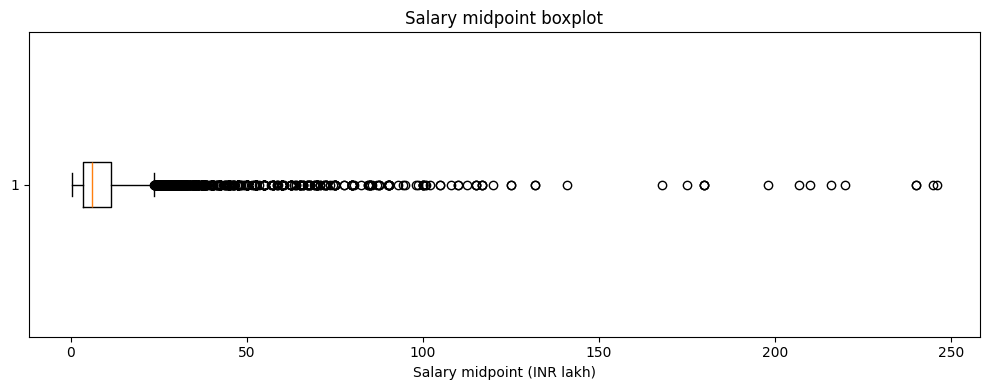

<Figure size 1100x500 with 0 Axes>

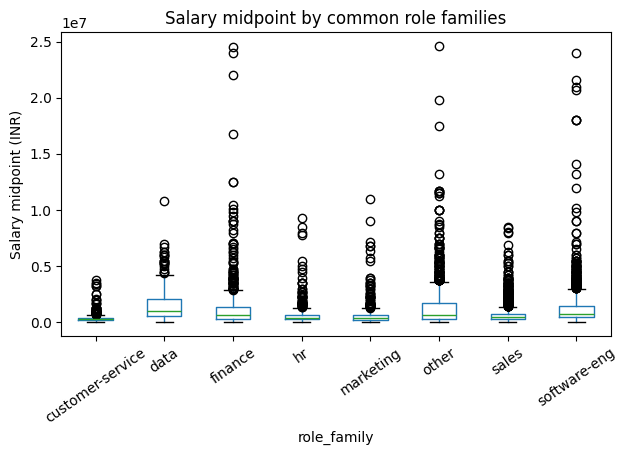

,count,median,mean
role_family,,,
data,478,1000000.0,1487186.0
software-eng,3242,750000.0,1185489.0
other,1835,650000.0,1274568.0
finance,736,650000.0,1348124.0
sales,1876,450000.0,716148.0
hr,501,400000.0,687611.0
marketing,569,400000.0,671729.0
customer-service,573,300000.0,393724.0


Interpretation: role-family differences are descriptive. They may reflect seniority, location, industry, and other confounding variables.


In [9]:
plt.figure(figsize=(10, 4))
plt.boxplot(salary_clean["salary_mid_inr"] / 100000, vert=False)
plt.xlabel("Salary midpoint (INR lakh)")
plt.title("Salary midpoint boxplot")
plt.tight_layout()
plt.show()

role_counts = salary_clean["role_family"].value_counts()
top_roles = role_counts.head(8).index
role_salary = salary_clean[salary_clean["role_family"].isin(top_roles)]
role_order = role_salary.groupby("role_family")["salary_mid_inr"].median().sort_values(ascending=False).index
plt.figure(figsize=(11, 5))
role_salary.boxplot(column="salary_mid_inr", by="role_family", rot=35, grid=False)
plt.ylabel("Salary midpoint (INR)")
plt.title("Salary midpoint by common role families")
plt.suptitle("")
plt.tight_layout()
plt.show()
display(role_salary.groupby("role_family")["salary_mid_inr"].agg(["count","median","mean"]).sort_values("median", ascending=False).round(0))
print("Interpretation: role-family differences are descriptive. They may reflect seniority, location, industry, and other confounding variables.")

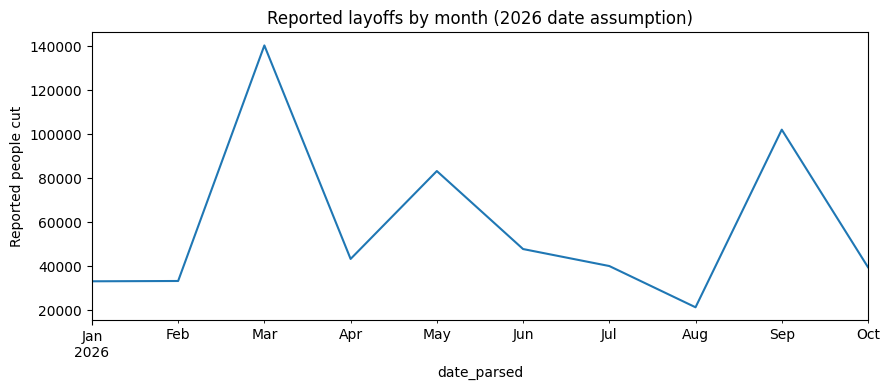

Note: this is the supplied file's snapshot, not necessarily a complete time series.


,count,sum,median
Industry,,,
Automotive & Transportation,60,206683,357.5
Tech,124,179759,250.0
Finance & Banking,49,91403,400.0
Consumer Goods,40,52725,222.0
Manufacturing,67,34243,168.0
Media & Entertainment,56,31616,124.0
Healthcare & Pharma,76,30487,147.0
Telecom,10,27598,795.0
Retail,38,27289,338.0


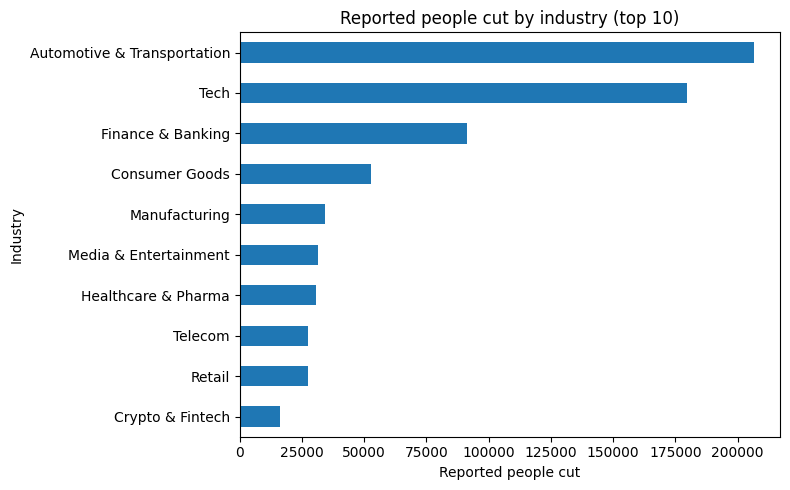

In [10]:

if {"date_parsed", "People Cut"}.issubset(layoffs_clean.columns):
    dated = layoffs_clean.dropna(subset=["date_parsed"]).copy()
    if len(dated):
        monthly = dated.set_index("date_parsed").resample("MS")["People Cut"].sum()
        plt.figure(figsize=(9, 4))
        monthly.plot()
        plt.ylabel("Reported people cut")
        plt.title("Reported layoffs by month (2026 date assumption)")
        plt.tight_layout()
        plt.show()
        print("Note: this is the supplied file's snapshot, not necessarily a complete time series.")
if {"Industry", "People Cut"}.issubset(layoffs_clean.columns):
    industry_layoffs = layoffs_clean.groupby("Industry")["People Cut"].agg(["count","sum","median"]).sort_values("sum", ascending=False).head(10)
    display(industry_layoffs)
    industry_layoffs["sum"].sort_values().plot(kind="barh", figsize=(8, 5), title="Reported people cut by industry (top 10)")
    plt.xlabel("Reported people cut")
    plt.tight_layout()
    plt.show()

# Sampling and Probability Distributions


,Statistic,Available dataset,Random sample (n=300)
0,Count,12958.00,300.00
1,Mean INR,1016846.91,1024068.33
2,Median INR,600000.00,600000.00
3,Standard deviation INR,1349484.98,1059307.60


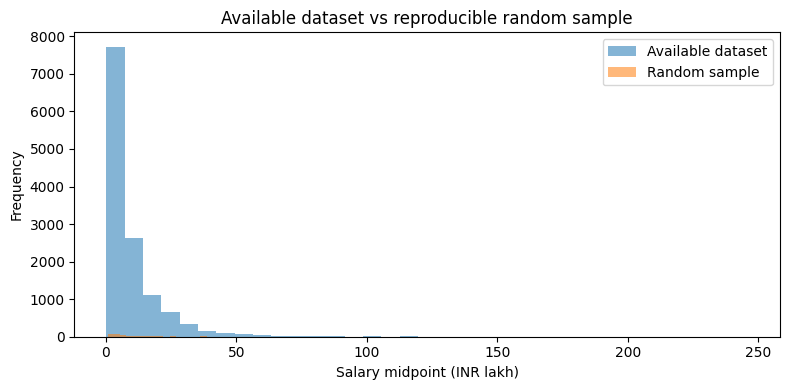

In [11]:
population_salary = salary_clean["salary_mid_inr"].dropna().to_numpy()
sample_size = min(300, len(population_salary))
sample_salary = salary_clean["salary_mid_inr"].sample(n=sample_size, random_state=SEED).to_numpy()
comparison = pd.DataFrame({
    "Statistic": ["Count", "Mean INR", "Median INR", "Standard deviation INR"],
    "Available dataset": [len(population_salary), np.mean(population_salary), np.median(population_salary), np.std(population_salary, ddof=1)],
    f"Random sample (n={sample_size})": [len(sample_salary), np.mean(sample_salary), np.median(sample_salary), np.std(sample_salary, ddof=1)]
})
display(comparison.round(2))
plt.figure(figsize=(8, 4))
plt.hist(population_salary / 100000, bins=35, alpha=0.55, label="Available dataset")
plt.hist(sample_salary / 100000, bins=25, alpha=0.55, label="Random sample")
plt.xlabel("Salary midpoint (INR lakh)")
plt.ylabel("Frequency")
plt.title("Available dataset vs reproducible random sample")
plt.legend()
plt.tight_layout()
plt.show()

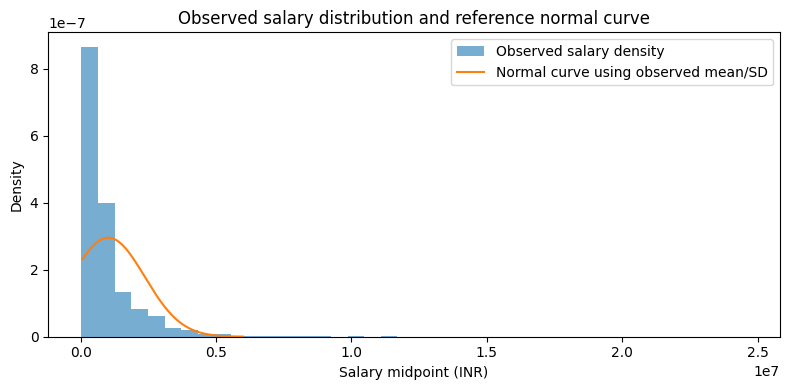

A mismatch between the histogram and curve suggests salaries may be skewed or heavy-tailed; the curve is only a reference.


In [12]:
# Distribution demonstration: a normal curve is fitted for visual comparison, not assumed to be true.
salary_mean = np.mean(population_salary)
salary_sd = np.std(population_salary, ddof=1)
x = np.linspace(np.quantile(population_salary, 0.01), np.quantile(population_salary, 0.99), 300)
plt.figure(figsize=(8, 4))
plt.hist(population_salary, bins=40, density=True, alpha=0.6, label="Observed salary density")
plt.plot(x, stats.norm.pdf(x, loc=salary_mean, scale=salary_sd), label="Normal curve using observed mean/SD")
plt.xlabel("Salary midpoint (INR)")
plt.ylabel("Density")
plt.title("Observed salary distribution and reference normal curve")
plt.legend()
plt.tight_layout()
plt.show()
print("A mismatch between the histogram and curve suggests salaries may be skewed or heavy-tailed; the curve is only a reference.")

# Central Limit Theorem (CLT)


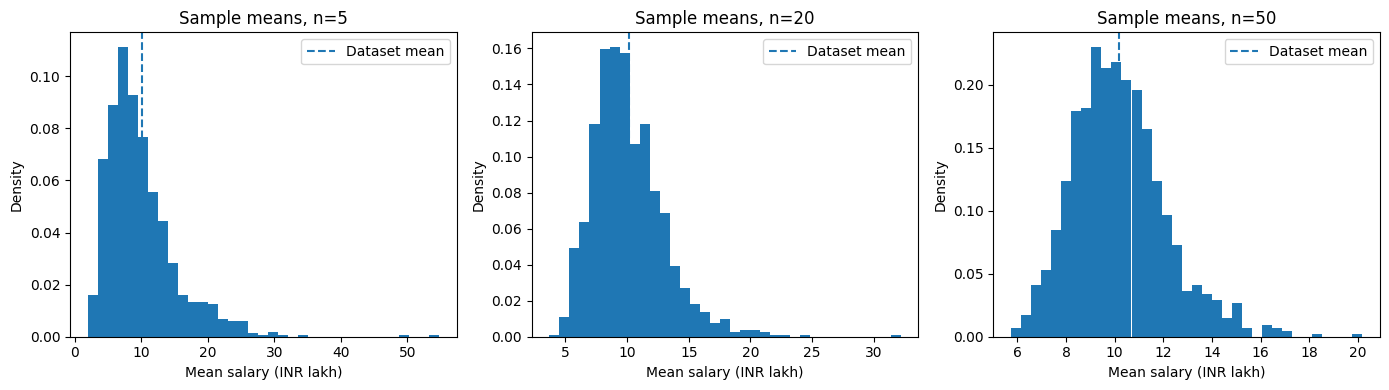

,sample_size,mean_of_sample_means,sd_of_sample_means,theoretical_standard_error
0,5,995797.56,536326.60,603508.03
1,20,1010466.68,292948.48,301754.01
2,50,1020142.04,192826.87,190846.00


Overall available-dataset mean: INR 1,016,847


In [13]:
sample_sizes = [5, 20, 50]
repetitions = 1000
clt_results = {}
for n in sample_sizes:
    means = [np.mean(np.random.choice(population_salary, size=n, replace=True)) for _ in range(repetitions)]
    clt_results[n] = np.array(means)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, n in zip(axes, sample_sizes):
    ax.hist(clt_results[n] / 100000, bins=35, density=True)
    ax.axvline(np.mean(population_salary)/100000, linestyle="--", label="Dataset mean")
    ax.set_title(f"Sample means, n={n}")
    ax.set_xlabel("Mean salary (INR lakh)")
    ax.set_ylabel("Density")
    ax.legend()
plt.tight_layout()
plt.show()

clt_summary = pd.DataFrame([
    {"sample_size": n, "mean_of_sample_means": means.mean(), "sd_of_sample_means": means.std(ddof=1),
     "theoretical_standard_error": np.std(population_salary, ddof=1) / np.sqrt(n)}
    for n, means in clt_results.items()
])
display(clt_summary.round(2))
print(f"Overall available-dataset mean: INR {np.mean(population_salary):,.0f}")

# Hypothesis Testing: t-test and z-test


In [14]:
# Hypothesis Testing: t-test and z-test

role_sizes = salary_clean["role_family"].value_counts()
eligible_roles = role_sizes[role_sizes >= 30].index.tolist()

if len(eligible_roles) >= 2:

    chosen_roles = role_sizes[eligible_roles].sort_values(ascending=False).head(2).index.tolist()

    group_a = salary_clean.loc[
        salary_clean["role_family"] == chosen_roles[0], "salary_mid_inr"
    ].dropna()

    group_b = salary_clean.loc[
        salary_clean["role_family"] == chosen_roles[1], "salary_mid_inr"
    ].dropna()

    # Independent two-sample Student's t-test
    t_stat, p_value = stats.ttest_ind(group_a, group_b, equal_var=True)

    print("Independent two-sample t-test")
    print("Group A:", chosen_roles[0], "| n =", len(group_a), "| Mean INR =", round(group_a.mean(), 2))
    print("Group B:", chosen_roles[1], "| n =", len(group_b), "| Mean INR =", round(group_b.mean(), 2))
    print(f"t-statistic = {t_stat:.4f}, p-value = {p_value:.6g}")

    if p_value < 0.05:
        print("Decision: Reject H0")
    else:
        print("Decision: Fail to reject H0")

    # Large-sample z-test approximation
    se = np.sqrt(
        group_a.var(ddof=1) / len(group_a)
        + group_b.var(ddof=1) / len(group_b)
    )

    z_stat = (group_a.mean() - group_b.mean()) / se
    z_p_value = 2 * stats.norm.sf(abs(z_stat))

    print("\nLarge-sample z-test approximation")
    print(f"z-statistic = {z_stat:.4f}, p-value = {z_p_value:.6g}")

else:
    print("Insufficient role groups for hypothesis testing.")

Independent two-sample t-test
Group A: software-eng | n = 3242 | Mean INR = 1185488.9
Group B: sales | n = 1876 | Mean INR = 716148.19
t-statistic = 13.3849, p-value = 3.49171e-40
Decision: Reject H0

Large-sample z-test approximation
z-statistic = 15.1626, p-value = 6.25894e-52


# One-Way ANOVA


,count,mean,median,std
role_family,,,,
finance,736,1348123.64,650000.0,2238127.86
other,1835,1274568.23,650000.0,1735202.29
software-eng,3242,1185488.90,750000.0,1379832.87
sales,1876,716148.19,450000.0,834121.44
customer-service,573,393724.26,300000.0,406767.73


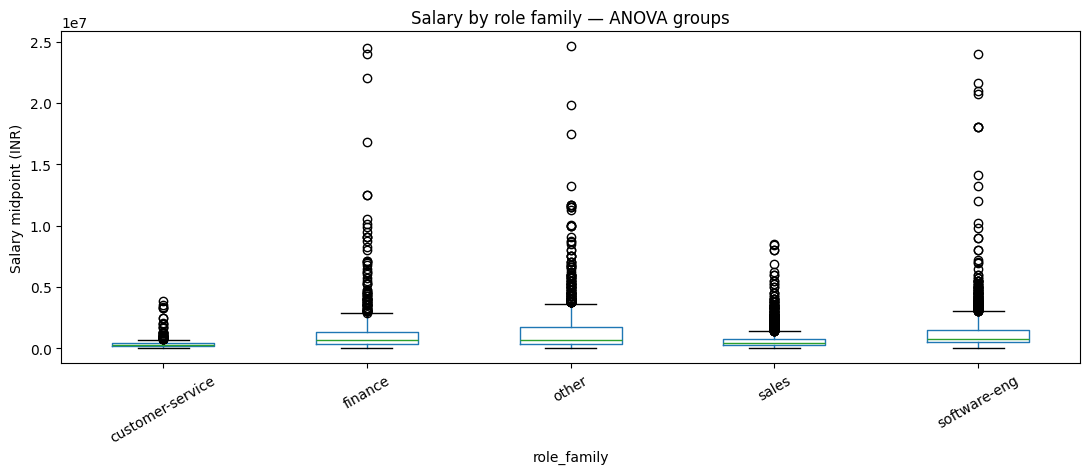

ANOVA F-statistic: 82.7963
p-value: 4.93786e-69
Reject H0: At least one group mean differs.


In [15]:
eligible = salary_clean["role_family"].value_counts()
eligible = eligible[eligible >= 30].head(5)

anova_groups = []

for role in eligible.index:
    salaries = salary_clean.loc[
        salary_clean["role_family"] == role, "salary_mid_inr"
    ].dropna().to_numpy()
    anova_groups.append(salaries)

if len(anova_groups) >= 3:
    f_stat, anova_p = stats.f_oneway(*anova_groups)

    anova_table = salary_clean[
        salary_clean["role_family"].isin(eligible.index)
    ].groupby("role_family")["salary_mid_inr"].agg(
        ["count", "mean", "median", "std"]
    ).sort_values("mean", ascending=False)

    display(anova_table.round(2))

    salary_clean[salary_clean["role_family"].isin(eligible.index)].boxplot(
        column="salary_mid_inr",
        by="role_family",
        rot=30,
        grid=False,
        figsize=(11, 5)
    )

    plt.title("Salary by role family — ANOVA groups")
    plt.suptitle("")
    plt.ylabel("Salary midpoint (INR)")
    plt.tight_layout()
    plt.show()

    print(f"ANOVA F-statistic: {f_stat:.4f}")
    print(f"p-value: {anova_p:.6g}")

    if anova_p < 0.05:
        print("Reject H0: At least one group mean differs.")
    else:
        print("Fail to reject H0: No significant difference found.")

else:
    print("Insufficient data for three role groups; ANOVA not performed.")

# Linear Regression

In [16]:
regression_data = salary_clean.dropna(subset=["month_index", "salary_mid_inr"]).copy()
X = regression_data[["month_index"]]
y = regression_data["salary_mid_inr"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)
y_pred = simple_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"Regression equation: predicted salary INR = {simple_model.intercept_:,.2f} + ({simple_model.coef_[0]:,.2f} × month_index)")
print(f"Coefficient: each one-month increase in month_index is associated with {simple_model.coef_[0]:,.2f} INR change in fitted salary midpoint, on average.")
print(f"MAE = INR {mae:,.2f}")
print(f"MSE = {mse:,.2f}")
print(f"RMSE = INR {rmse:,.2f}")
print(f"R² = {r2:.4f}")
print("Observed predictor range:", int(X_train["month_index"].min()), "to", int(X_train["month_index"].max()))

Regression equation: predicted salary INR = -543,588,112.68 + (22,402.66 × month_index)
Coefficient: each one-month increase in month_index is associated with 22,402.66 INR change in fitted salary midpoint, on average.
MAE = INR 765,155.30
MSE = 1,571,296,408,588.51
RMSE = INR 1,253,513.63
R² = 0.0171
Observed predictor range: 24289 to 24318


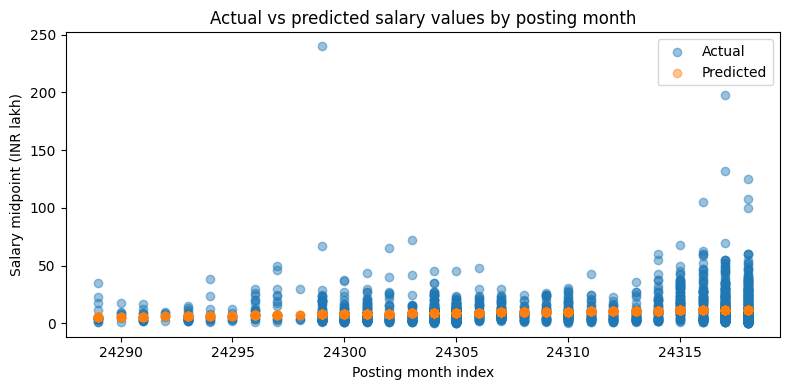

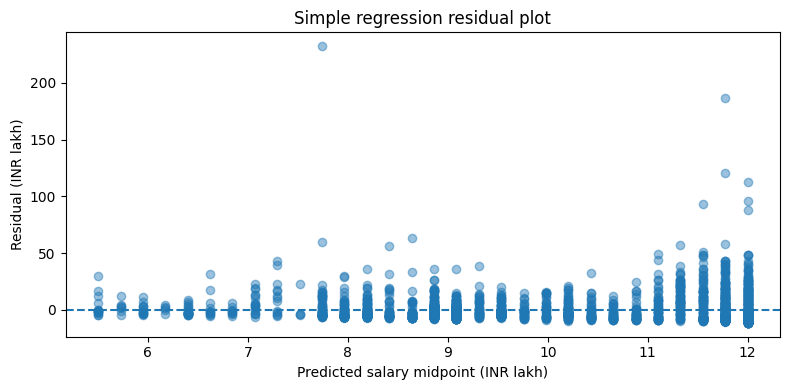

Residual mean: 11664.1 INR


In [17]:
plt.figure(figsize=(8, 4))
plt.scatter(X_test["month_index"], y_test/100000, alpha=0.45, label="Actual")
plt.scatter(X_test["month_index"], y_pred/100000, alpha=0.45, label="Predicted")
plt.xlabel("Posting month index")
plt.ylabel("Salary midpoint (INR lakh)")
plt.title("Actual vs predicted salary values by posting month")
plt.legend()
plt.tight_layout()
plt.show()

residuals = y_test.to_numpy() - y_pred
plt.figure(figsize=(8, 4))
plt.scatter(y_pred/100000, residuals/100000, alpha=0.45)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted salary midpoint (INR lakh)")
plt.ylabel("Residual (INR lakh)")
plt.title("Simple regression residual plot")
plt.tight_layout()
plt.show()
print("Residual mean:", round(float(np.mean(residuals)), 2), "INR")

### Gradio salary predictor

In [18]:

import gradio as gr
import pandas as pd

# Map readable month labels to the numeric indexes used for training
month_data = (
    salary_clean[["posted_month", "month_index"]]
    .dropna()
    .drop_duplicates()
    .sort_values("month_index")
)

month_options = [
    (str(row["posted_month"]), int(row["month_index"]))
    for _, row in month_data.iterrows()
]

def predict_salary(selected_month):
    month_index = int(selected_month)

    estimate = simple_model.predict(
        pd.DataFrame({"month_index": [month_index]})
    )[0]

    if estimate <= 0:
        return (
            f"The model predicted INR {estimate:,.0f}, "
            "which is not a realistic salary estimate. "
            "The regression model needs improvement."
        )

    return f"Estimated annual salary: INR {estimate:,.0f}"

interface = gr.Interface(
    fn=predict_salary,
    inputs=gr.Dropdown(
        choices=month_options,
        label="Select Posting Month"
    ),
    outputs="text",
    title="Salary Prediction System",
    description="Select a posting month to estimate the annual salary midpoint."
)

if RUN_GRADIO_DEMO:
    interface.launch(share=False)
else:
    print("Gradio demo is ready. Set RUN_GRADIO_DEMO = True in the setup cell to launch it.")


Gradio demo is ready. Set RUN_GRADIO_DEMO = True in the setup cell to launch it.


# Multiple Linear Regression


In [19]:
candidate_features = ["month_index", "role_family", "seniority", "city", "industry_category"]

features = []
for col in candidate_features:
    if col in salary_clean.columns:
        features.append(col)

model_data = salary_clean[features + ["salary_mid_inr"]].dropna(
    subset=["salary_mid_inr"]
).copy()

numeric_features = []
categorical_features = []

for col in features:
    if col == "month_index":
        numeric_features.append(col)
    else:
        categorical_features.append(col)
        model_data[col] = model_data[col].fillna("Unknown").astype(str)

print("Predictors used:", features)
print("Target: salary_mid_inr (INR)")
print("Modeling rows:", len(model_data))

Predictors used: ['month_index', 'role_family', 'seniority', 'city', 'industry_category']
Target: salary_mid_inr (INR)
Modeling rows: 12958


In [20]:
X_multi = model_data[features]
y_multi = model_data["salary_mid_inr"]
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=SEED)

numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))
])
transformers = []
if numeric_features:
    transformers.append(("num", numeric_transformer, numeric_features))
if categorical_features:
    transformers.append(("cat", categorical_transformer, categorical_features))
preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
multiple_model = Pipeline(steps=[("preprocessor", preprocessor), ("regressor", LinearRegression())])
multiple_model.fit(X_train_m, y_train_m)
y_pred_m = multiple_model.predict(X_test_m)

mae_m = mean_absolute_error(y_test_m, y_pred_m)
mse_m = mean_squared_error(y_test_m, y_pred_m)
rmse_m = np.sqrt(mse_m)
r2_m = r2_score(y_test_m, y_pred_m)
metrics_table = pd.DataFrame([
    {"Model":"Simple regression (posting month only)", "MAE_INR":mae, "MSE_INR2":mse, "RMSE_INR":rmse, "R2":r2},
    {"Model":"Multiple regression (month + categories)", "MAE_INR":mae_m, "MSE_INR2":mse_m, "RMSE_INR":rmse_m, "R2":r2_m}
])
display(metrics_table.round(4))

,Model,MAE_INR,MSE_INR2,RMSE_INR,R2
0,Simple regression (posting month only),765155.3003,1.571296e+12,1.253514e+06,0.0171
1,Multiple regression (month + categories),586311.5769,1.128991e+12,1.062540e+06,0.2938


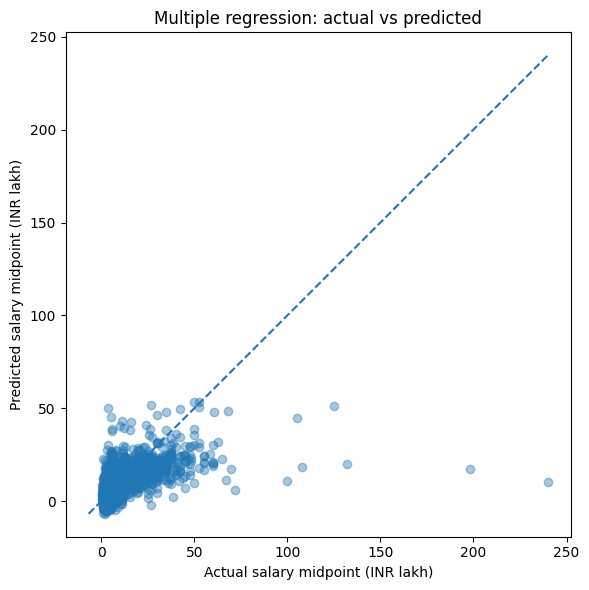

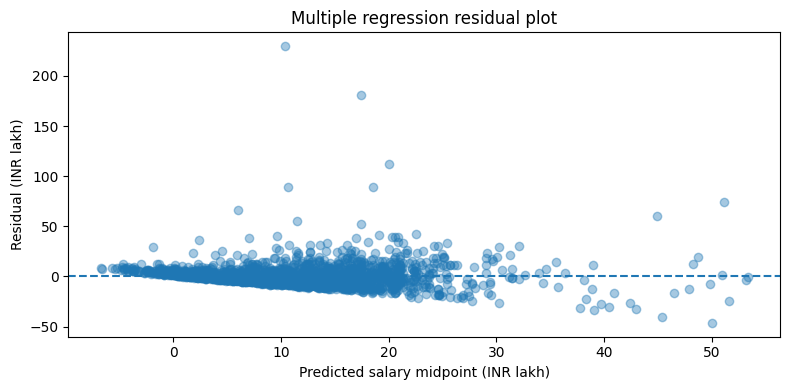

Multiple model residual mean: -5603.69 INR


In [21]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_m/100000, y_pred_m/100000, alpha=0.4)
low = min(float(y_test_m.min()), float(np.min(y_pred_m))) / 100000
high = max(float(y_test_m.max()), float(np.max(y_pred_m))) / 100000
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual salary midpoint (INR lakh)")
plt.ylabel("Predicted salary midpoint (INR lakh)")
plt.title("Multiple regression: actual vs predicted")
plt.tight_layout()
plt.show()

residuals_m = y_test_m.to_numpy() - y_pred_m
plt.figure(figsize=(8, 4))
plt.scatter(y_pred_m/100000, residuals_m/100000, alpha=0.4)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted salary midpoint (INR lakh)")
plt.ylabel("Residual (INR lakh)")
plt.title("Multiple regression residual plot")
plt.tight_layout()
plt.show()
print("Multiple model residual mean:", round(float(np.mean(residuals_m)), 2), "INR")